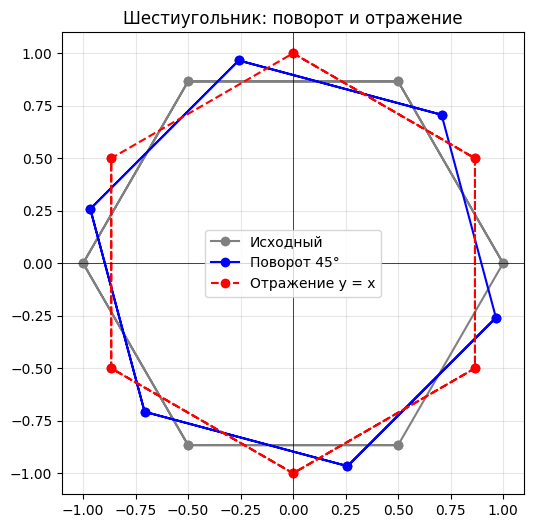

In [9]:
#Задание 1
import numpy as np
import matplotlib.pyplot as plt

k = np.arange(6)
x = np.cos(2 * np.pi * k / 6)
y = np.sin(2 * np.pi * k / 6)

pts = np.column_stack((x, y))
pts = np.vstack((pts, pts))

a = np.radians(45)
rot_mat = np.array((
    (np.cos(a), -np.sin(a)),
    (np.sin(a),  np.cos(a))
))

ref_mat = np.array((
    (0, 1),
    (1, 0)
))

pts_rot = pts @ rot_mat.T
pts_ref = pts @ ref_mat.T

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(pts[:, 0], pts[:, 1], 'o-', color='gray', label='Исходный')
ax.plot(pts_rot[:, 0], pts_rot[:, 1], 'o-', color='blue', label='Поворот 45°')
ax.plot(pts_ref[:, 0], pts_ref[:, 1], 'o--', color='red', label='Отражение y = x')

ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title('Шестиугольник: поворот и отражение')

plt.show()


Правильный шестиугольник симметричен, поэтому после зеркального отражения относительно прямой y = x (когда координаты x и y меняются местами) его вершины попадают на те же места, что и при повороте на 30 или 90 градусов (меняется только порядок обхода). Матрица отражения отличается от матрицы поворота на 90 градусов только знаком одного элемента

Точки совпали с точностью 1e-12: True


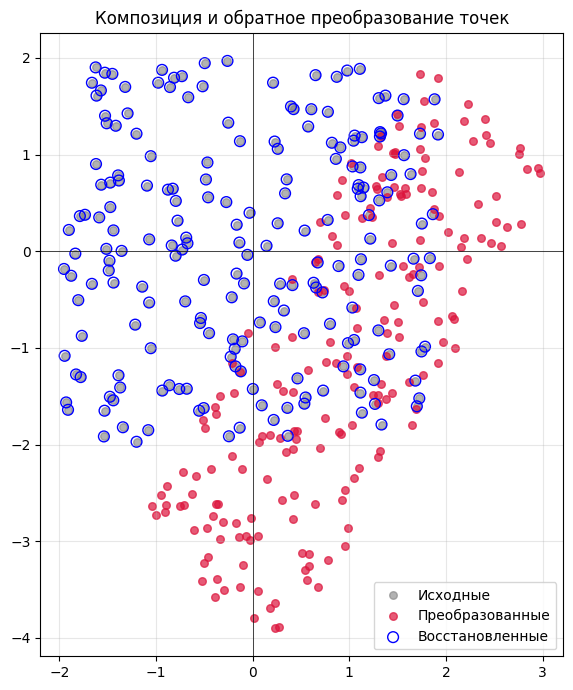

In [10]:
#Задание 2
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
pts = rng.uniform(-2, 2, size=(200, 2))

pts_h = np.column_stack((pts, np.ones(len(pts))))

# Прямые матрицы 3x3
S = np.array((
    (1.5, 0.0, 0.0),
    (0.0, 0.5, 0.0),
    (0.0, 0.0, 1.0)
))

a = np.radians(60)
R = np.array((
    (np.cos(a), -np.sin(a), 0.0),
    (np.sin(a),  np.cos(a), 0.0),
    (0.0,        0.0,       1.0)
))

T = np.array((
    (1.0, 0.0,  1.0),
    (0.0, 1.0, -1.0),
    (0.0, 0.0,  1.0)
))

M_forward = T @ R @ S
pts_trans = (pts_h @ M_forward.T)[:, :2]

T_inv = np.array((
    (1.0, 0.0, -1.0),
    (0.0, 1.0,  1.0),
    (0.0, 0.0,  1.0)
))

a_inv = np.radians(-60)
R_inv = np.array((
    (np.cos(a_inv), -np.sin(a_inv), 0.0),
    (np.sin(a_inv),  np.cos(a_inv), 0.0),
    (0.0,            0.0,           1.0)
))

S_inv = np.array((
    (1 / 1.5, 0.0,     0.0),
    (0.0,     1 / 0.5, 0.0),
    (0.0,     0.0,     1.0)
))

M_backward = S_inv @ R_inv @ T_inv
pts_trans_h = np.column_stack((pts_trans, np.ones(len(pts_trans))))
pts_restored = (pts_trans_h @ M_backward.T)[:, :2]

# Проверка точности
is_exact = np.allclose(pts, pts_restored, atol=1e-12)
print("Точки совпали с точностью 1e-12:", is_exact)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pts[:, 0], pts[:, 1], color="gray", alpha=0.6, s=30, label="Исходные")
ax.scatter(pts_trans[:, 0], pts_trans[:, 1], color="crimson", alpha=0.7, s=30, label="Преобразованные")
ax.scatter(pts_restored[:, 0], pts_restored[:, 1], facecolors="none", edgecolors="blue", s=60, label="Восстановленные")

ax.axhline(0, color="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Композиция и обратное преобразование точек")

plt.tight_layout()
plt.show()


Почему в обратном порядке - умножение матриц зависит от порядка поэтому обратная матрица от произведения разворачивает порядок действий. Чтобы вернуть точки в исходное состояние нужно сначала отменить последнее действие, то есть перенос, затем поворот и только потом масштаб

Что будет в прямом порядке - если сначала применить обратный масштаб к уже повёрнутой и сдвинутой фигуре сжатие произойдёт вдоль обычных осей координат, а не осей самой фигуры и сдвиг также исказится. В итоге облако точек сместится в сторону и не вернётся в исходный квадрат